# Fundamentos teóricos

En este capítulo resolvemos analíticamente los seis puntos de 4.8.23 y verificamos cada resultado con una celda de código. Las verificaciones usan las mismas funciones del paquete `src/project` que usa el resto del proyecto.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import softmax
from scipy.stats import norm
from IPython.display import Markdown, display

from project import calibration as cal
from project import metrics_seg as ms
from project.book_utils import CAT, MUTED, need, style

style()
rng = np.random.default_rng(2026)

## 1. Relación entre Dice e IoU

Sean $A$ la predicción y $B$ la referencia, con $I = |A\cap B|$ y $U = |A\cup B|$. Por inclusión–exclusión, $|A|+|B| = U + I$. Entonces

$$
D = \frac{2I}{|A|+|B|} = \frac{2I}{U+I} = \frac{2\,(I/U)}{1 + I/U} = \frac{2J}{1+J}.
$$

La función $f(J) = 2J/(1+J)$ es estrictamente creciente en $[0,1]$, porque $f'(J) = 2/(1+J)^2 > 0$. Para un mismo par imagen–referencia, ordenar predicciones por Dice o por IoU da el mismo orden.

Al promediar sobre imágenes la conclusión cambia. $f$ es cóncava, con $f''(J) = -4/(1+J)^3 < 0$, y por la desigualdad de Jensen $\overline{f(J_i)} \le f(\overline{J_i})$. La brecha depende de la dispersión de los $J_i$, así que dos modelos con distinta dispersión pueden invertir su orden.

**Contraejemplo.** El modelo A obtiene $J = (0.5, 0.5)$ en dos imágenes y el modelo B obtiene $J = (0.05, 1.0)$. El IoU medio es 0.500 para A y 0.525 para B: gana B. El Dice medio es 0.667 para A y 0.548 para B: gana A. Lo verificamos con máscaras reales y la función `dice_iou` del proyecto.

In [2]:
def mask_pair(j_target, n=10_000):
    """Par de máscaras 1-D (como imagen 100×100) con IoU exacto j_target: |B| = n/2, intersección ajustada."""
    b = np.zeros(n, bool); b[: n // 2] = True
    # A = primeros k píxeles de B + m píxeles fuera de B; con m = 0, J = k / |B|
    k = int(round(j_target * n / 2)); a = np.zeros(n, bool); a[:k] = True
    return a.reshape(100, 100), b.reshape(100, 100)

res, raw = [], []
for model, js in (("A", (0.5, 0.5)), ("B", (0.05, 1.0))):
    d, j = zip(*[ms.dice_iou(*mask_pair(t)) for t in js])
    raw += list(zip(d, j))
    res.append(dict(modelo=model, IoU_por_imagen=np.round(j, 3), Dice_por_imagen=np.round(d, 3),
                    IoU_medio=np.mean(j), Dice_medio=np.mean(d)))
tab = pd.DataFrame(res); display(tab)
assert all(abs(dd - 2 * jj / (1 + jj)) < 1e-6 for dd, jj in raw)
assert tab.IoU_medio[1] > tab.IoU_medio[0] and tab.Dice_medio[1] < tab.Dice_medio[0]
display(Markdown("Verificado: $D = 2J/(1+J)$ en cada imagen, y el orden de A y B se invierte al promediar."))

,modelo,IoU_por_imagen,Dice_por_imagen,IoU_medio,Dice_medio
0,A,"[0.5, 0.5]","[0.667, 0.667]",0.500,0.666667
1,B,"[0.05, 1.0]","[0.095, 1.0]",0.525,0.547619


Verificado: $D = 2J/(1+J)$ en cada imagen, y el orden de A y B se invierte al promediar.

## 2. Gradiente de la pérdida Dice suave

Con $N = 2\sum_j p_j g_j + \epsilon$ y $M = \sum_j p_j + \sum_j g_j + \epsilon$, la pérdida es $\mathcal{L} = 1 - N/M$. Por la regla del cociente, con $\partial N/\partial p_i = 2g_i$ y $\partial M/\partial p_i = 1$:

$$
\frac{\partial \mathcal{L}}{\partial p_i} = -\frac{2 g_i M - N}{M^2} = \frac{N - 2 g_i M}{M^2}.
$$

Para un píxel de fondo ($g_i = 0$) el gradiente es $N/M^2 \ge 0$ y empuja $p_i$ hacia abajo. Para un píxel de primer plano ($g_i=1$) es $(N - 2M)/M^2 < 0$, porque $N \le 2M$, y empuja $p_i$ hacia arriba. El gradiente de cada píxel depende de sumas globales y no de su propio error. Cuando el primer plano ocupa una fracción $\pi$ mínima de la imagen y la red predice poco primer plano, $M$ es pequeño y el gradiente escala como $1/M$: es grande e inestable al inicio del entrenamiento, pero no queda dominado por el fondo. Esa normalización global es lo que hace a Dice robusta al desbalance.

Con entropía cruzada binaria promediada sobre $n$ píxeles y salida sigmoide $p_i = \sigma(z_i)$, el gradiente respecto al *logit* es $(p_i - g_i)/n$: local y acotado. La suma de gradientes del fondo crece con $(1-\pi)\,n$ y domina cuando $\pi \to 0$. La pérdida focal multiplica cada término por $(1-p_{t,i})^\gamma$, donde $p_{t,i}$ es la probabilidad asignada a la clase correcta. Así atenúa los píxeles fáciles (casi todo el fondo) sin normalizar globalmente.

Verificamos la fórmula analítica contra diferencias finitas centradas y comparamos la magnitud del gradiente en el primer plano para varios $\pi$.

In [3]:
def dice_loss(p, g, eps=1.0):
    return 1 - (2 * (p * g).sum() + eps) / (p.sum() + g.sum() + eps)

def dice_grad(p, g, eps=1.0):
    N = 2 * (p * g).sum() + eps; M = p.sum() + g.sum() + eps
    return (N - 2 * g * M) / M**2

n = 4096
g = (rng.random(n) < 0.05).astype(float); p = rng.random(n) * 0.3
h = 1e-6; num = np.array([(dice_loss(p + h * (np.arange(n) == i), g) - dice_loss(p - h * (np.arange(n) == i), g)) / (2 * h) for i in range(200)])
err = np.max(np.abs(num - dice_grad(p, g)[:200]))
display(Markdown(f"Error máximo entre gradiente analítico y diferencias finitas (200 píxeles): **{err:.2e}**."))
assert err < 1e-6

rows = []
for pi in (0.5, 0.1, 0.01, 0.001):
    g = (rng.random(n * 16) < pi).astype(float); p = np.full_like(g, 0.1)
    fg = g == 1
    ce = (p - g) / len(g)                         # gradiente de BCE respecto al logit
    gamma = 2.0; pt = np.where(fg, p, 1 - p)
    fl = ce * (1 - pt) ** gamma                    # aproximación de primer orden del peso focal
    dg = dice_grad(p, g)
    rows.append({"π": pi, "|∂L/∂p| Dice (1.er plano)": np.abs(dg[fg]).mean(), "Σ|grad| fondo / Σ|grad| 1.er plano, BCE":
                 np.abs(ce[~fg]).sum() / np.abs(ce[fg]).sum(), "ídem, focal γ=2": np.abs(fl[~fg]).sum() / np.abs(fl[fg]).sum(),
                 "ídem, Dice": np.abs(dg[~fg]).sum() / np.abs(dg[fg]).sum()})
pd.DataFrame(rows)

Error máximo entre gradiente analítico y diferencias finitas (200 píxeles): **1.15e-11**.

,π,|∂L/∂p| Dice (1.er plano),"Σ|grad| fondo / Σ|grad| 1.er plano, BCE","ídem, focal γ=2","ídem, Dice"
0,0.500,0.000046,0.109489,0.001352,0.089713
1,0.100,0.000144,0.990519,0.012229,0.471648
2,0.010,0.000275,11.126200,0.137360,0.916154
3,0.001,0.000302,137.280922,1.694826,1.085471


Con $\pi = 0.001$ y una predicción inicial de 0.1 en todos los píxeles, en BCE el fondo aporta 137 veces más gradiente total que el primer plano. En Dice el cociente queda entre 0.09 y 1.09 para todos los $\pi$, y el gradiente por píxel de primer plano crece de 4.6·10⁻⁵ a 3.0·10⁻⁴ a medida que $\pi$ baja. La pérdida focal reduce el dominio del fondo en unas 80 veces frente a BCE (cociente de 1.7 con $\pi = 0.001$). Por eso la U-Net++ combina entropía cruzada (gradiente estable y local) con Dice (insensible al desbalance), y la ablación del capítulo 14 compara las cuatro pérdidas.

## 3. Desbalance y métricas de píxel

Sea $\pi$ la proporción de píxeles de célula. El clasificador trivial que predice «fondo» en todo píxel tiene:

- exactitud $= 1 - \pi \to 1$ cuando $\pi \to 0$;
- *balanced accuracy* $= \tfrac12(\text{TPR} + \text{TNR}) = \tfrac12(0 + 1) = 0.5$, independiente de $\pi$;
- AUC-ROC $= 0.5$, porque su puntuación es constante.

Para un clasificador casi trivial, con puntuación $s \sim \mathcal{N}(d'\,y, 1)$, el AUC-ROC es $\Phi(d'/\sqrt2)$, que **no depende de $\pi$**: la curva ROC solo usa tasas condicionadas a la clase. La precisión sí depende de $\pi$: $\text{Prec} = \pi\,\text{TPR}/(\pi\,\text{TPR} + (1-\pi)\,\text{FPR})$. Cuando $\pi \to 0$, cualquier FPR positivo la lleva a 0, y el área bajo la curva PR de un clasificador aleatorio es $\pi$. La curva PR expone el costo de los falsos positivos en el régimen desbalanceado, y la ROC no.

In [4]:
from sklearn.metrics import average_precision_score, balanced_accuracy_score, roc_auc_score

rows = []
for pi in (0.5, 0.2, 0.05, 0.01, 0.001):
    y = (rng.random(200_000) < pi).astype(int)
    trivial = np.zeros_like(y)
    s = rng.normal(1.0 * y, 1.0)
    rows.append({"π": pi, "exactitud (trivial)": (trivial == y).mean(), "balanced acc. (trivial)": balanced_accuracy_score(y, trivial),
                 "AUC-ROC (d'=1)": roc_auc_score(y, s), "AUC-ROC teórico": norm.cdf(1 / np.sqrt(2)),
                 "AP / PR-AUC (d'=1)": average_precision_score(y, s), "AP aleatorio": average_precision_score(y, rng.random(len(y)))})
pd.DataFrame(rows)

,π,exactitud (trivial),balanced acc. (trivial),AUC-ROC (d'=1),AUC-ROC teórico,AP / PR-AUC (d'=1),AP aleatorio
0,0.500,0.499230,0.5,0.760414,0.76025,0.752036,0.499847
1,0.200,0.798865,0.5,0.761317,0.76025,0.464636,0.200727
2,0.050,0.949295,0.5,0.759418,0.76025,0.177636,0.050752
3,0.010,0.990040,0.5,0.753843,0.76025,0.040967,0.010093
4,0.001,0.998960,0.5,0.727043,0.76025,0.004244,0.001123


La simulación confirma la teoría: la exactitud del trivial tiende a 1, su *balanced accuracy* queda en 0.5 y el AUC-ROC del clasificador débil se mantiene cerca de 0.76 (con $\pi = 0.001$ hay unos 200 positivos y la estimación se aleja del valor teórico por variación muestral), mientras su AP cae de 0.75 a 0.004.

En Sartorius $\pi$ va de 0.02 (corticales) a 0.20 (SH-SY5Y). En corticales, un AUC-ROC de píxel alto convive con una precisión baja. Esto anticipa la hipótesis H2: AUC y *balanced accuracy* de píxel saturan y no discriminan entre modelos, mientras AP@[0.5:0.95] sí.

## 4. Sesgo optimista de la validación al buscar hiperparámetros

Si evaluamos $K$ configuraciones en la misma validación y reportamos la mejor, reportamos $\max_k \hat{R}_k$, donde $\hat{R}_k = R_k + e_k$ es el rendimiento verdadero más un error de estimación. Aunque cada $\hat R_k$ sea insesgado, $\mathbb{E}[\max_k \hat R_k] \ge \max_k \mathbb{E}[\hat R_k]$: el máximo selecciona configuraciones con error positivo. El sesgo crece con $K$ y con la varianza de la validación, que es grande con pocos ejemplos por clase {cite:p}`varma2006bias,cawley2010overfitting`.

La validación anidada separa dos funciones: el lazo interno elige hiperparámetros con su propia partición, y el pliegue externo, que nunca participó en la elección, mide el rendimiento. Su estimación es (casi) insesgada para el procedimiento completo de «buscar y entrenar».

Primero ilustramos el mecanismo con una simulación sin señal: 30 «configuraciones» que aciertan al azar el 50 % de 373 ejemplos de validación.

In [5]:
K, nval, reps = 30, 373, 5000
best = (rng.random((reps, K, nval)) < 0.5).mean(axis=2).max(axis=1)
display(Markdown(f"Exactitud verdadera 0.500; media del máximo de {K} configuraciones en validación: **{best.mean():.3f}** "
                 f"(sesgo de +{best.mean() - 0.5:.3f})."))

Exactitud verdadera 0.500; media del máximo de 30 configuraciones en validación: **0.553** (sesgo de +0.053).

Después lo estimamos en un modelo real: TF-IDF + regresión logística en Jarvis. Comparamos la mejor F1 macro de validación de la búsqueda TPE (30 *trials*) con la F1 macro de los pliegues externos de la validación anidada (5 pliegues externos, 30 *trials* internos cada uno).

In [6]:
hpo = need("nlp/tfidf_lr/hpo/hpo.pkl")
nested = need("nlp/tfidf_lr/nested/nested.pkl")["folds"]
from project.stats import bootstrap_ci
est, lo, hi = bootstrap_ci(nested.outer_f1_macro.to_numpy())
inner = nested.inner_best.mean()
display(pd.DataFrame({"estimación": ["mejor F1 macro de validación (HPO simple)", "media del mejor interno (anidada)",
                                     "F1 macro externa (anidada)"],
                      "valor": [hpo["best_value"], inner, est]}))
display(Markdown(f"Sesgo optimista de la HPO simple frente a la anidada: **{hpo['best_value'] - est:+.3f}** "
                 f"(IC 95 % de la estimación anidada: [{lo:.3f}, {hi:.3f}]); "
                 f"sesgo dentro de la anidada (interno − externo): **{inner - est:+.3f}**."))

,estimación,valor
0,mejor F1 macro de validación (HPO simple),0.658620
1,media del mejor interno (anidada),0.642555
2,F1 macro externa (anidada),0.629801


Sesgo optimista de la HPO simple frente a la anidada: **+0.029** (IC 95 % de la estimación anidada: [0.609, 0.655]); sesgo dentro de la anidada (interno − externo): **+0.013**.

## 5. Calibración, ECE y Brier

Con $N$ ejemplos, $K$ clases, probabilidades $\hat p_{ik}$ y etiquetas *one-hot* $y_{ik}$, agrupamos los ejemplos en $B$ intervalos según su confianza $\hat c_i = \max_k \hat p_{ik}$:

$$
\text{ECE} = \sum_{b=1}^{B} \frac{|S_b|}{N}\,\bigl|\text{acc}(S_b) - \text{conf}(S_b)\bigr|, \qquad
\text{Brier} = \frac1N \sum_{i=1}^N \sum_{k=1}^K (\hat p_{ik} - y_{ik})^2 .
$$

**El escalado de temperatura no altera el argmax.** Para $T > 0$, $\operatorname{softmax}(z/T)_k = e^{z_k/T} / \sum_j e^{z_j/T}$. El denominador es común a todas las clases y $u \mapsto e^{u/T}$ es estrictamente creciente, de modo que $z_k > z_l \iff \operatorname{softmax}(z/T)_k > \operatorname{softmax}(z/T)_l$. El orden de las clases se conserva, el argmax es el mismo y la exactitud no cambia.

**Pero sí cambia la NLL.** $\text{NLL}(T) = -\frac1N\sum_i \bigl[z_{i,y_i}/T - \log\sum_j e^{z_{ij}/T}\bigr]$ depende de $T$: con $T \to 0$ las probabilidades se vuelven *one-hot* y la NLL de cada error tiende a infinito; con $T \to \infty$ tienden a $1/K$ y la NLL a $\log K$. El escalado de temperatura elige $T$ minimizando la NLL en validación {cite:p}`guo2017calibration`.

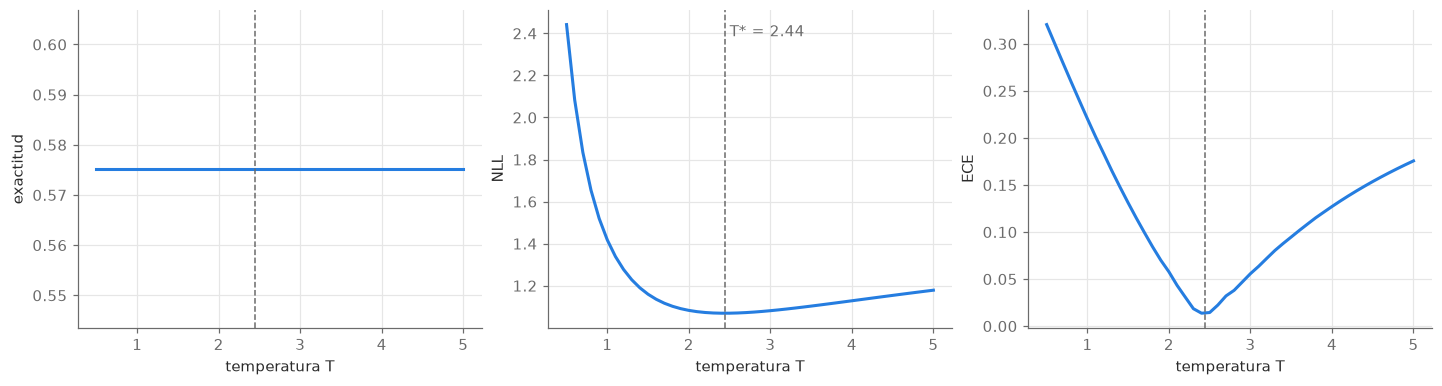

La exactitud es constante (0.575) para todo $T$; la NLL baja de 2.442 (T = 0.5) a 1.069 en $T^*$ = 2.44, cerca del factor de inflado 2.5.

In [7]:
Kc, nn = 5, 5000
z = rng.normal(0, 1.5, (nn, Kc)); y = np.array([rng.choice(Kc, p=pp) for pp in softmax(z, 1)])
logits = 2.5 * z                                        # modelo sobreconfiado: logits inflados
Ts = np.linspace(0.5, 5, 46)
acc = [(softmax(logits / t, 1).argmax(1) == y).mean() for t in Ts]
nll = [cal.nll(softmax(logits / t, 1), y) for t in Ts]
ece = [cal.expected_calibration_error(softmax(logits / t, 1), y) for t in Ts]
T_star = cal.fit_temperature(logits, y)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, v, lab in zip(axes, (acc, nll, ece), ("exactitud", "NLL", "ECE")):
    ax.plot(Ts, v, color=CAT[0]); ax.axvline(T_star, color=MUTED, ls="--", lw=1); ax.set(xlabel="temperatura T", ylabel=lab)
axes[1].text(T_star, max(nll), f" T* = {T_star:.2f}", color=MUTED, va="top")
plt.show()
assert np.ptp(acc) == 0
display(Markdown(f"La exactitud es constante ({acc[0]:.3f}) para todo $T$; la NLL baja de {nll[0]:.3f} (T = 0.5) a "
                 f"{cal.nll(softmax(logits / T_star, 1), y):.3f} en $T^*$ = {T_star:.2f}, cerca del factor de inflado 2.5."))

## 6. Complejidad computacional

**U-Net++.** Cada convolución $k\times k$ en el nivel $l$ procesa $\frac{HW}{4^l}$ posiciones con $C_l = C_0 2^l$ canales, con un costo de $O\!\left(\frac{HW}{4^l} k^2 C_l^2\right) = O(HW\,k^2 C_0^2)$ por nivel. Con profundidad $L$ y $O(L^2)$ nodos anidados, el tiempo es $O(L^2\,HW\,k^2C_0^2)$, **lineal en el número de píxeles**. La memoria de activaciones también es $O(HW\,C_0 L^2)$.

**BiLSTM.** Cada paso calcula cuatro compuertas, con un costo de $O(4(d\,h + h^2))$ por dirección. Con longitud $T$, el tiempo es $O(T(dh + h^2))$, lineal en $T$ pero **secuencial**: los $T$ pasos no se paralelizan. La memoria para BPTT es $O(T\,h)$.

**Auto-atención.** Las proyecciones cuestan $O(T d^2)$. El producto $QK^\top$ y la ponderación de $V$ cuestan $O(T^2 d)$. El tiempo es $O(T^2 d + T d^2)$, y la memoria de la matriz de atención es $O(T^2)$, **cuadrática** en la longitud. Todo se paraleliza a lo largo de $T$.

Medimos tiempo de inferencia (mediana de 10 repeticiones) y memoria pico de GPU. La pendiente en escala log–log, estimada en la mitad superior de tamaños, aproxima el exponente.

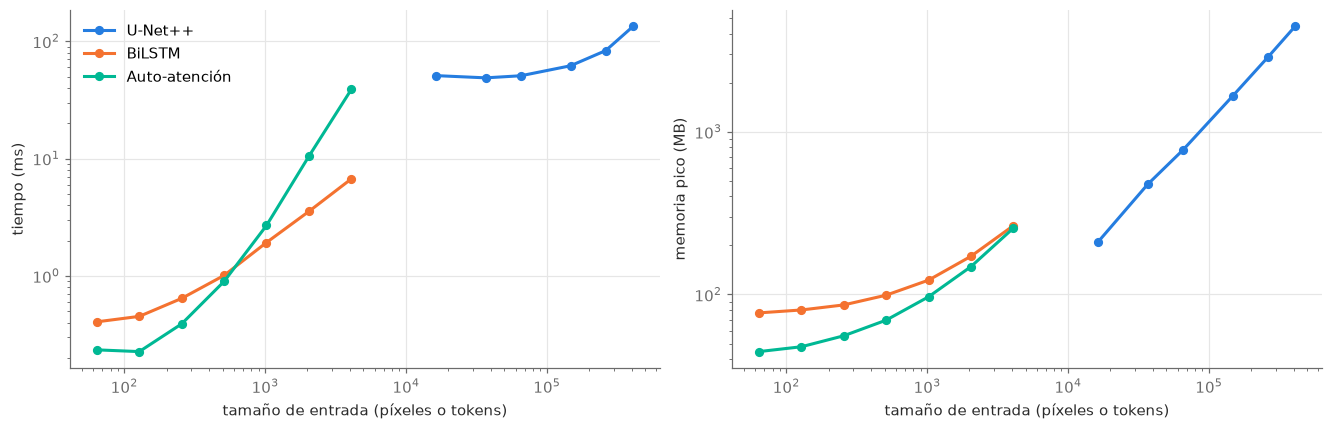

,pendiente del tiempo,pendiente de la memoria,teórica (tiempo)
Auto-atención,1.83,0.62,1 a 2 (2 si T ≫ d)
BiLSTM,0.91,0.47,1
U-Net++,0.74,0.97,1 (en píxeles)


Dispositivo: NVIDIA GeForce RTX 4060 Laptop GPU.

**Auto-atención.** La pendiente del tiempo es 1.83: con T hasta 4096 y d = 256, el término O(T²d) domina al O(Td²) y la pendiente se acerca a 2. La pendiente de la memoria, 0.62, queda lejos del 2 que predice la matriz de atención: en inferencia y sin pedir los pesos (`need_weights=False`), `torch.nn.MultiheadAttention` usa núcleos fusionados que calculan el *softmax* por bloques sin guardar la matriz T × T, así que la memoria crece con las activaciones O(Td). La memoria cuadrática vale para la implementación directa y para el entrenamiento que guarda la matriz para el gradiente. **BiLSTM.** Tiempo con pendiente 0.91, cercana al 1 teórico. La memoria crece más despacio (0.47) porque en inferencia no se guardan los estados para BPTT y los pesos y las entradas suman una parte fija. **U-Net++.** Memoria con pendiente 0.97, lineal en píxeles como predice el análisis. El tiempo crece con pendiente 0.74, por debajo de 1: con imágenes de hasta 640 × 640 la GPU no está saturada y el costo fijo por llamada (lanzamiento de núcleos y `predict_on_batch` de Keras) pesa en los tamaños pequeños. El exponente teórico es asintótico y la pendiente medida se acerca a él cuando la imagen crece. Validez: inferencia con lote fijo en una GPU de portátil; en entrenamiento, la memoria de los tres modelos incluye además las activaciones guardadas para el gradiente.

In [8]:
cx = need("analysis/complexity/complexity.pkl")
d = cx["rows"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for i, (mname, g) in enumerate(d.groupby("model", sort=False)):
    axes[0].loglog(g.n, g.seconds * 1e3, "o-", color=CAT[i], label=mname, ms=5)
    axes[1].loglog(g.n, g.peak_mb, "o-", color=CAT[i], label=mname, ms=5)
axes[0].set(xlabel="tamaño de entrada (píxeles o tokens)", ylabel="tiempo (ms)"); axes[0].legend()
axes[1].set(xlabel="tamaño de entrada (píxeles o tokens)", ylabel="memoria pico (MB)")
plt.show()
fits = pd.DataFrame(cx["fits"]).T.rename(columns={"time_slope": "pendiente del tiempo", "mem_slope": "pendiente de la memoria"})
fits["teórica (tiempo)"] = fits.index.map({"U-Net++": "1 (en píxeles)", "BiLSTM": "1", "Auto-atención": "1 a 2 (2 si T ≫ d)"})
display(fits.round(2)); display(Markdown(f"Dispositivo: {cx['device']}."))
_f = cx["fits"]
_txt = []
if "Auto-atención" in _f:
    a = _f["Auto-atención"]
    _txt.append(
        f"**Auto-atención.** La pendiente del tiempo es {a['time_slope']:.2f}: con T hasta 4096 y d = 256, el término O(T²d) "
        f"domina al O(Td²) y la pendiente se acerca a 2. "
        + (f"La pendiente de la memoria, {a['mem_slope']:.2f}, queda lejos del 2 que predice la matriz de atención: en inferencia y sin "
           "pedir los pesos (`need_weights=False`), `torch.nn.MultiheadAttention` usa núcleos fusionados que calculan el *softmax* por "
           "bloques sin guardar la matriz T × T, así que la memoria crece con las activaciones O(Td). La memoria cuadrática vale para "
           "la implementación directa y para el entrenamiento que guarda la matriz para el gradiente."
           if a["mem_slope"] < 1.5 else
           f"La pendiente de la memoria, {a['mem_slope']:.2f}, refleja la matriz de atención O(T²)."))
if "BiLSTM" in _f:
    b = _f["BiLSTM"]
    _txt.append(f"**BiLSTM.** Tiempo con pendiente {b['time_slope']:.2f}, cercana al 1 teórico. La memoria crece más despacio "
                f"({b['mem_slope']:.2f}) porque en inferencia no se guardan los estados para BPTT y los pesos y las entradas "
                "suman una parte fija.")
if "U-Net++" in _f:
    u = _f["U-Net++"]
    _txt.append(f"**U-Net++.** Memoria con pendiente {u['mem_slope']:.2f}, lineal en píxeles como predice el análisis. El tiempo crece "
                f"con pendiente {u['time_slope']:.2f}, por debajo de 1: con imágenes de hasta 640 × 640 la GPU no está saturada y el "
                "costo fijo por llamada (lanzamiento de núcleos y `predict_on_batch` de Keras) pesa en los tamaños pequeños. El "
                "exponente teórico es asintótico y la pendiente medida se acerca a él cuando la imagen crece.")
display(Markdown(" ".join(_txt) + " Validez: inferencia con lote fijo en una GPU de portátil; en entrenamiento, la memoria de "
                 "los tres modelos incluye además las activaciones guardadas para el gradiente."))